In [1]:
from pathlib import Path

import pandas as pd

from dataset import prepare_client_data, TARGET, DROP_COLS

# ============================================================
# 1. KONFIGURASI
# ============================================================
CLIENT_DIR = Path(r'C:\Users\s2\Documents\FIXRKI\bfprssprep\split\clients')

# ============================================================
# 2. MUAT DATA SEMUA CLIENT (scaling + konversi ke tensor)
# ============================================================
clients, scaler, feature_names = prepare_client_data(CLIENT_DIR)

print(f"Jumlah client : {len(clients)}")
print(f"Daftar state  : {list(clients.keys())}")
print(f"Target        : {TARGET}")
print(f"Kolom dibuang : {DROP_COLS}")

# ============================================================
# 3. DAFTAR FITUR YANG DIPAKAI
# ============================================================
n_fitur = next(iter(clients.values()))['X_train_t'].shape[1]
assert n_fitur == len(feature_names), "Jumlah fitur tidak cocok dengan nama fitur"

print(f"\nJumlah fitur  : {n_fitur}")
for i, nama in enumerate(feature_names, 1):
    print(f"{i:>3}. {nama}")

# ============================================================
# 4. RINGKASAN TIAP CLIENT
# ============================================================
rows = {}
for st, c in clients.items():
    rows[st] = {
        'n_train':   len(c['y_train_t']),
        'n_val':     len(c['y_val_t']),
        'n_test':    len(c['y_test_t']),
        'pos_train': int(c['y_train_t'].sum()),
        'pos_val':   int(c['y_val_t'].sum()),
        'pos_test':  int(c['y_test_t'].sum()),
    }

ringkas = pd.DataFrame(rows).T
ringkas.index.name = 'state'

for s in ('train', 'val', 'test'):
    ringkas[f'pos_{s}_%'] = (100 * ringkas[f'pos_{s}'] / ringkas[f'n_{s}']).round(2)

# Baris total
total = ringkas[[c for c in ringkas.columns if not c.endswith('%')]].sum()
for s in ('train', 'val', 'test'):
    total[f'pos_{s}_%'] = round(100 * total[f'pos_{s}'] / total[f'n_{s}'], 2)
ringkas.loc['TOTAL'] = total

print("\nRingkasan per client:")
print(ringkas.to_string())

Jumlah client : 44
Daftar state  : [1, 2, 4, 5, 8, 10, 11, 12, 13, 15, 16, 17, 18, 19, 20, 22, 23, 24, 25, 26, 27, 29, 30, 31, 33, 34, 35, 36, 37, 38, 39, 40, 41, 44, 45, 46, 48, 49, 50, 51, 53, 54, 55, 56]
Target        : _michd
Kolom dibuang : ['iyear', '_state', 'cvdinfr4', 'cvdcrhd4']

Jumlah fitur  : 69
  1. sexvar
  2. _age80
  3. _educag
  4. income3
  5. veteran3
  6. children
  7. _urbstat
  8. _bmi5
  9. diabete4
 10. medcost1
 11. checkup1
 12. genhlth
 13. physhlth
 14. menthlth
 15. exerany2
 16. cvdstrk3
 17. chcscnc1
 18. chcocnc1
 19. chccopd3
 20. addepev3
 21. chckdny2
 22. havarth4
 23. diabage4
 24. deaf
 25. blind
 26. decide
 27. diffwalk
 28. diffdres
 29. diffalon
 30. _rfbing6
 31. drnkany6
 32. flushot7
 33. pneuvac4
 34. marital_1
 35. marital_2
 36. marital_3
 37. marital_4
 38. marital_5
 39. marital_6
 40. employ1_1
 41. employ1_2
 42. employ1_3
 43. employ1_4
 44. employ1_5
 45. employ1_6
 46. employ1_7
 47. employ1_8
 48. renthom1_1
 49. renthom1_2
 50. 

In [2]:

# ============================================================
# 4. FUNGSI AMBIL X, y UNTUK SATU CLIENT
# ============================================================
def get_xy(st, split):
    c = clients[st]
    return c[f'X_{split}_t'], c[f'y_{split}_t']

# ============================================================
# 5. CONTOH PEMAKAIAN
# ============================================================
st = next(iter(clients))
X_train, y_train = get_xy(st, 'train')
X_val,   y_val   = get_xy(st, 'val')
X_test,  y_test  = get_xy(st, 'test')

print(f"\nState {st}")
print("Train:", tuple(X_train.shape), "| Val:", tuple(X_val.shape), "| Test:", tuple(X_test.shape))
print("Distribusi label train:\n", pd.Series(y_train.numpy()).value_counts())

# ============================================================
# 6. CONTOH LOOP SEMUA CLIENT (kerangka federated learning)
# ============================================================
for st in clients:
    X_tr, y_tr = get_xy(st, 'train')
    X_va, y_va = get_xy(st, 'val')
    # TODO: latih model lokal client `st` di sini
    print(f"state_{st:02d} -> train {tuple(X_tr.shape)}, val {tuple(X_va.shape)}")


State 1
Train: (979, 69) | Val: (562, 69) | Test: (581, 69)
Distribusi label train:
 0    743
1    236
Name: count, dtype: int64
state_01 -> train (979, 69), val (562, 69)
state_02 -> train (644, 69), val (358, 69)
state_04 -> train (1781, 69), val (804, 69)
state_05 -> train (1076, 69), val (595, 69)
state_08 -> train (927, 69), val (646, 69)
state_10 -> train (686, 69), val (414, 69)
state_11 -> train (345, 69), val (199, 69)
state_12 -> train (2330, 69), val (1257, 69)
state_13 -> train (1605, 69), val (695, 69)
state_15 -> train (1361, 69), val (591, 69)
state_16 -> train (791, 69), val (283, 69)
state_17 -> train (727, 69), val (1224, 69)
state_18 -> train (1906, 69), val (1350, 69)
state_19 -> train (1589, 69), val (870, 69)
state_20 -> train (1684, 69), val (914, 69)
state_22 -> train (1009, 69), val (415, 69)
state_23 -> train (1763, 69), val (1003, 69)
state_24 -> train (2845, 69), val (1310, 69)
state_25 -> train (1046, 69), val (537, 69)
state_26 -> train (1525, 69), val (1

In [3]:
total_train = sum(len(c['y_train_t']) for c in clients.values())
print(scaler.n_samples_seen_, total_train)   # keduanya harus sama

59971 59971


In [4]:
# %%
# ============================================================
# 7. IMPOR + KONFIGURASI TRAINING LOKAL
#    (taruh di bawah cell terakhir notebook Anda)
# ============================================================
import copy

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score)

from model import build_model

DEVICE     = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
EPOCHS     = 50
BATCH_SIZE = 64
LR         = 1e-3
PATIENCE   = 5          # early stopping berdasarkan val loss
SEED       = 42

print("Device:", DEVICE)

# %%
# ============================================================
# 8. FUNGSI TRAIN & EVALUASI
# ============================================================
def make_loader(X, y, shuffle):
    ds = TensorDataset(X.float(), y.long())
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle)


@torch.no_grad()
def evaluate(model, X, y, criterion=None):
    """Kembalikan dict metrik (+ loss jika criterion diberikan)."""
    model.eval()
    X, y = X.float().to(DEVICE), y.long().to(DEVICE)
    logits = model(X)
    prob = torch.softmax(logits, dim=1)[:, 1].cpu().numpy()
    pred = logits.argmax(dim=1).cpu().numpy()
    y_np = y.cpu().numpy()

    out = {
        'acc':  accuracy_score(y_np, pred),
        'prec': precision_score(y_np, pred, zero_division=0),
        'rec':  recall_score(y_np, pred, zero_division=0),
        'f1':   f1_score(y_np, pred, zero_division=0),
        # AUC tidak terdefinisi jika hanya ada 1 kelas di y
        'auc':  roc_auc_score(y_np, prob) if len(np.unique(y_np)) > 1 else np.nan,
    }
    if criterion is not None:
        out['loss'] = criterion(logits, y).item()
    return out


def train_local(X_train, y_train, X_val, y_val, verbose=False):
    """Latih satu model lokal; kembalikan (model terbaik, history)."""
    model = build_model(in_dim=X_train.shape[1], seed=SEED).to(DEVICE)

    # Class weight untuk mengatasi imbalance (pos_rate tiap state berbeda)
    n_pos = int(y_train.sum())
    n_neg = len(y_train) - n_pos
    if n_pos > 0 and n_neg > 0:
        w = torch.tensor([len(y_train) / (2 * n_neg),
                          len(y_train) / (2 * n_pos)], dtype=torch.float32)
    else:
        w = torch.ones(2)
    criterion = nn.CrossEntropyLoss(weight=w.to(DEVICE))
    optimizer = torch.optim.Adam(model.parameters(), lr=LR)

    loader = make_loader(X_train, y_train, shuffle=True)

    best_loss, best_state, wait = float('inf'), None, 0
    history = []

    for epoch in range(1, EPOCHS + 1):
        model.train()
        running = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            optimizer.zero_grad()
            loss = criterion(model(xb), yb)
            loss.backward()
            optimizer.step()
            running += loss.item() * len(xb)
        train_loss = running / len(loader.dataset)

        val = evaluate(model, X_val, y_val, criterion)
        history.append({'epoch': epoch, 'train_loss': train_loss,
                        'val_loss': val['loss'], 'val_f1': val['f1']})
        if verbose:
            print(f"  ep {epoch:02d} | train {train_loss:.4f} | "
                  f"val {val['loss']:.4f} | val_f1 {val['f1']:.4f}")

        # Early stopping
        if val['loss'] < best_loss - 1e-5:
            best_loss, wait = val['loss'], 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            wait += 1
            if wait >= PATIENCE:
                break

    model.load_state_dict(best_state)
    return model, pd.DataFrame(history)

# %%
# ============================================================
# 9. LATIH SEMUA CLIENT (LOKAL, TANPA AGREGASI)
# ============================================================
local_models, local_hist, rows = {}, {}, []

for st in clients:
    X_tr, y_tr = get_xy(st, 'train')
    X_va, y_va = get_xy(st, 'val')
    X_te, y_te = get_xy(st, 'test')

    model, hist = train_local(X_tr, y_tr, X_va, y_va)
    test = evaluate(model, X_te, y_te)

    local_models[st] = model
    local_hist[st]   = hist
    rows.append({'state': st, 'epochs_run': len(hist), **test})
    print(f"state_{st:02d} | epochs {len(hist):02d} | "
          f"acc {test['acc']:.4f} | f1 {test['f1']:.4f} | auc {test['auc']:.4f}")

hasil_lokal = pd.DataFrame(rows).set_index('state')
print("\n=== Hasil test tiap client (model lokal) ===")
print(hasil_lokal.round(4).to_string())
print("\nRata-rata:\n", hasil_lokal.drop(columns='epochs_run').mean().round(4))

# # %%
# # ============================================================
# # 10. SIMPAN BOBOT (theta & phi) UNTUK TAHAP FEDERATED / ANALISIS
# # ============================================================
# SAVE_DIR = CLIENT_DIR.parent / 'local_models'
# SAVE_DIR.mkdir(exist_ok=True)
# for st, m in local_models.items():
#     torch.save(m.state_dict(), SAVE_DIR / f'local_state_{st}.pt')
# hasil_lokal.to_csv(SAVE_DIR / 'hasil_lokal.csv')
# print("Tersimpan di:", SAVE_DIR)

Device: cuda
state_01 | epochs 11 | acc 0.6420 | f1 0.4611 | auc 0.7282
state_02 | epochs 11 | acc 0.6761 | f1 0.4425 | auc 0.6791
state_04 | epochs 08 | acc 0.6485 | f1 0.4642 | auc 0.7555
state_05 | epochs 10 | acc 0.6691 | f1 0.5263 | auc 0.7340
state_08 | epochs 10 | acc 0.6705 | f1 0.3734 | auc 0.7018
state_10 | epochs 10 | acc 0.6718 | f1 0.4622 | auc 0.6985
state_11 | epochs 14 | acc 0.7600 | f1 0.4000 | auc 0.8032
state_12 | epochs 07 | acc 0.6630 | f1 0.4782 | auc 0.7254
state_13 | epochs 08 | acc 0.7010 | f1 0.5613 | auc 0.7843
state_15 | epochs 08 | acc 0.6150 | f1 0.3708 | auc 0.6731
state_16 | epochs 12 | acc 0.6117 | f1 0.3750 | auc 0.7007
state_17 | epochs 10 | acc 0.6427 | f1 0.4515 | auc 0.7222
state_18 | epochs 08 | acc 0.6504 | f1 0.4512 | auc 0.7306
state_19 | epochs 08 | acc 0.6490 | f1 0.4974 | auc 0.7452
state_20 | epochs 08 | acc 0.6309 | f1 0.4366 | auc 0.7337
state_22 | epochs 08 | acc 0.6500 | f1 0.4558 | auc 0.7492
state_23 | epochs 10 | acc 0.6566 | f1 0.49

=== Metrik per client ===
       Akurasi  Presisi  Recall  F1-score     AUC  n_test
state                                                    
1       0.6420   0.3490  0.6794    0.4611  0.7282     581
2       0.6761   0.3521  0.5952    0.4425  0.6791     389
4       0.6485   0.3375  0.7431    0.4642  0.7555     532
5       0.6691   0.4292  0.6803    0.5263  0.7340     544
8       0.6705   0.2719  0.5960    0.3734  0.7018     601
10      0.6718   0.3642  0.6322    0.4622  0.6985     390
11      0.7600   0.2909  0.6400    0.4000  0.8032     200
12      0.6630   0.3752  0.6589    0.4782  0.7254    1276
13      0.7010   0.4359  0.7881    0.5613  0.7843     622
15      0.6150   0.2649  0.6174    0.3708  0.6731     626
16      0.6117   0.2963  0.5106    0.3750  0.7007     206
17      0.6427   0.3370  0.6840    0.4515  0.7222    1251
18      0.6504   0.3288  0.7185    0.4512  0.7306     675
19      0.6490   0.3750  0.7382    0.4974  0.7452     812
20      0.6309   0.3136  0.7184    0.4366  0.7

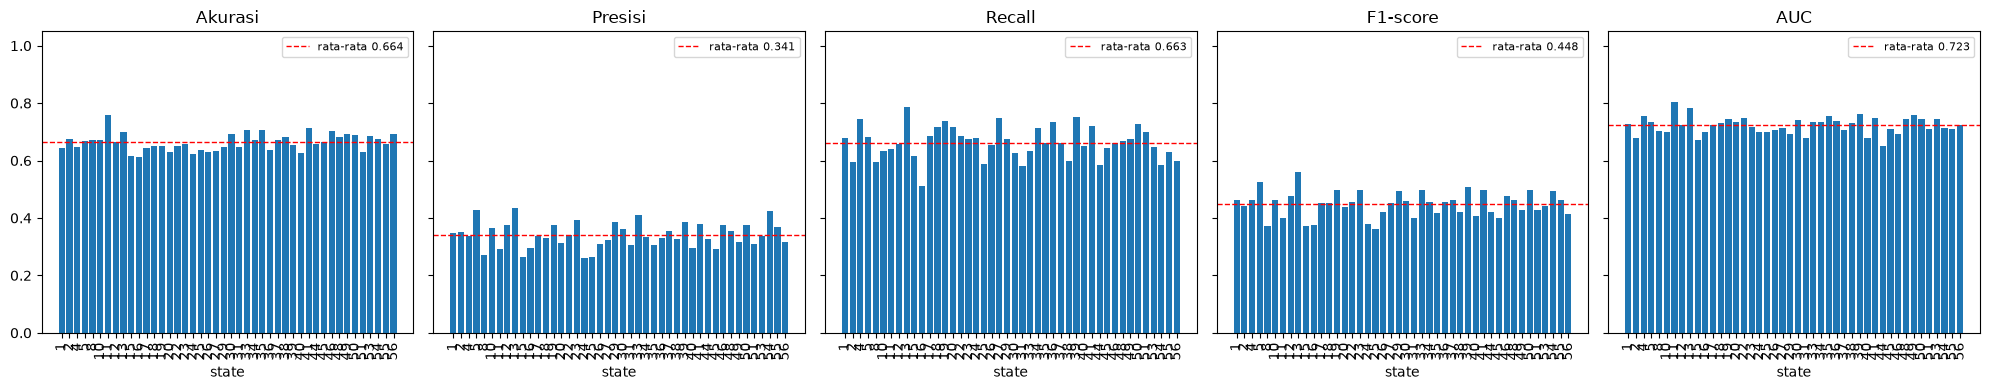

In [5]:
# %%
# ============================================================
# 11. RINGKASAN METRIK KINERJA (TEST SET, MODEL LOKAL)
#     Akurasi, Presisi, Recall, F1-score, AUC
# ============================================================
import matplotlib.pyplot as plt

METRIK = ['acc', 'prec', 'rec', 'f1', 'auc']
NAMA   = {'acc': 'Akurasi', 'prec': 'Presisi', 'rec': 'Recall',
          'f1': 'F1-score', 'auc': 'AUC'}

tabel = hasil_lokal[METRIK].copy()
tabel['n_test'] = [len(clients[st]['y_test_t']) for st in tabel.index]

# --- Rata-rata makro (tiap client bobot sama) & berbobot (menurut n_test)
makro = tabel[METRIK].mean()
std   = tabel[METRIK].std()
bobot = tabel['n_test'] / tabel['n_test'].sum()
berbobot = (tabel[METRIK].mul(bobot, axis=0)).sum()   # NaN AUC diabaikan oleh sum

ringkasan = pd.DataFrame({
    'Rata-rata (makro)':    makro,
    'Std antar client':     std,
    'Rata-rata berbobot':   berbobot,
    'Min':                  tabel[METRIK].min(),
    'Max':                  tabel[METRIK].max(),
}).rename(index=NAMA)

print("=== Metrik per client ===")
print(tabel.rename(columns=NAMA).round(4).to_string())
print("\n=== Ringkasan antar client ===")
print(ringkasan.round(4).to_string())

# --- Visualisasi: bar chart tiap metrik per client
fig, axes = plt.subplots(1, len(METRIK), figsize=(4 * len(METRIK), 4), sharey=True)
for ax, m in zip(axes, METRIK):
    ax.bar(tabel.index.astype(str), tabel[m])
    ax.axhline(makro[m], color='red', ls='--', lw=1, label=f'rata-rata {makro[m]:.3f}')
    ax.set_title(NAMA[m])
    ax.set_xlabel('state')
    ax.set_ylim(0, 1.05)
    ax.tick_params(axis='x', labelrotation=90)
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

# --- Simpan (opsional)
# tabel.to_csv(CLIENT_DIR.parent / 'metrik_lokal.csv')

=== RANKING STATE (urut F1 tertinggi) ===
       rank_f1  rata2_rank     acc    prec     rec      f1     auc  n_train  n_val  n_test  pos_train  pos_rate_train%  pos_test  pos_rate_test%
state                                                                                                                                           
13           1         2.2  0.7010  0.4359  0.7881  0.5613  0.7843     1605    695     622        342            21.31       151           24.28
5            2        10.8  0.6691  0.4292  0.6803  0.5263  0.7340     1076    595     544        279            25.93       147           27.02
39           3         8.2  0.6547  0.3850  0.7500  0.5088  0.7619     2757   1057     973        666            24.16       232           23.84
33           4        12.0  0.7058  0.4108  0.6333  0.4984  0.7335      992    589     520        215            21.67       120           23.08
19           5        11.8  0.6490  0.3750  0.7382  0.4974  0.7452     1589    870     8

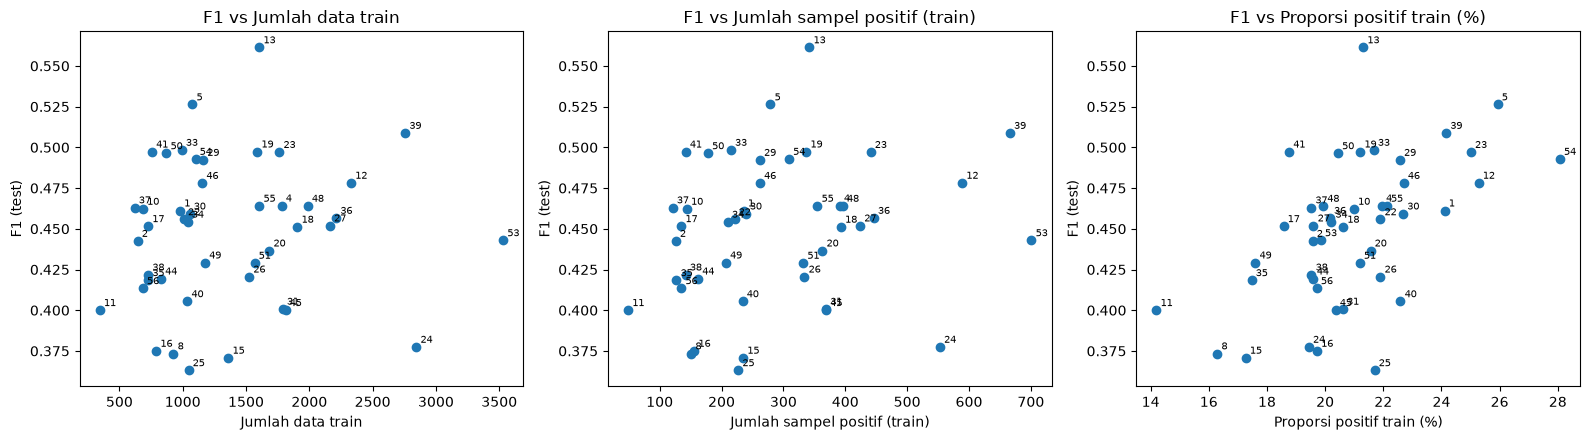

In [6]:
# %%
# ============================================================
# 12. RANKING STATE BERDASARKAN KINERJA + INFO JUMLAH DATA
#     (jalankan setelah cell 9 / 11)
# ============================================================
import matplotlib.pyplot as plt

METRIK = ['acc', 'prec', 'rec', 'f1', 'auc']

# --- 12a. Info jumlah data tiap state
info = pd.DataFrame({
    st: {
        'n_train':    len(c['y_train_t']),
        'n_val':      len(c['y_val_t']),
        'n_test':     len(c['y_test_t']),
        'pos_train':  int(c['y_train_t'].sum()),
        'pos_test':   int(c['y_test_t'].sum()),
    }
    for st, c in clients.items()
}).T
info['n_total']         = info[['n_train', 'n_val', 'n_test']].sum(axis=1)
info['pos_rate_train%'] = (100 * info['pos_train'] / info['n_train']).round(2)
info['pos_rate_test%']  = (100 * info['pos_test']  / info['n_test']).round(2)
info.index.name = 'state'

# --- 12b. Gabungkan dengan metrik
gabung = hasil_lokal[METRIK].join(info)

# --- 12c. Ranking: utama F1 (tie-breaker AUC), plus rata-rata rank semua metrik
gabung['rank_f1'] = (gabung[['f1', 'auc']]
                     .apply(tuple, axis=1)
                     .rank(ascending=False, method='min').astype(int))
rank_per_metrik = gabung[METRIK].rank(ascending=False, method='min')
gabung['rata2_rank'] = rank_per_metrik.mean(axis=1).round(2)
gabung = gabung.sort_values(['rank_f1', 'rata2_rank'])

kolom_tampil = (['rank_f1', 'rata2_rank'] + METRIK +
                ['n_train', 'n_val', 'n_test', 'pos_train', 'pos_rate_train%',
                 'pos_test', 'pos_rate_test%'])

print("=== RANKING STATE (urut F1 tertinggi) ===")
print(gabung[kolom_tampil].round(4).to_string())

N = min(5, len(gabung))
print(f"\n=== {N} STATE TERBAIK ===")
print(gabung[kolom_tampil].head(N).round(4).to_string())
print(f"\n=== {N} STATE TERENDAH ===")
print(gabung[kolom_tampil].tail(N).round(4).to_string())

# --- 12d. Profil data: kelompok atas vs bawah
atas, bawah = gabung.head(N), gabung.tail(N)
profil = pd.DataFrame({
    f'Top {N}':    atas[['n_train', 'n_test', 'pos_rate_train%']].mean(),
    f'Bottom {N}': bawah[['n_train', 'n_test', 'pos_rate_train%']].mean(),
    'Semua state': gabung[['n_train', 'n_test', 'pos_rate_train%']].mean(),
}).round(2)
print("\n=== PROFIL DATA RATA-RATA (atas vs bawah) ===")
print(profil.to_string())

# --- 12e. Korelasi Spearman: apakah ukuran/proporsi data memengaruhi kinerja?
korelasi = gabung[['n_train', 'pos_train', 'pos_rate_train%',
                   'f1', 'rec', 'auc']].corr(method='spearman')
print("\n=== KORELASI SPEARMAN (data vs kinerja) ===")
print(korelasi.loc[['n_train', 'pos_train', 'pos_rate_train%'],
                   ['f1', 'rec', 'auc']].round(3).to_string())

# --- 12f. Visualisasi
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, x, judul in zip(axes,
                        ['n_train', 'pos_train', 'pos_rate_train%'],
                        ['Jumlah data train', 'Jumlah sampel positif (train)',
                         'Proporsi positif train (%)']):
    ax.scatter(gabung[x], gabung['f1'])
    for st, row in gabung.iterrows():
        ax.annotate(str(st), (row[x], row['f1']), fontsize=7,
                    xytext=(3, 3), textcoords='offset points')
    ax.set_xlabel(judul)
    ax.set_ylabel('F1 (test)')
    ax.set_title(f'F1 vs {judul}')
plt.tight_layout()
plt.show()

# --- Simpan (opsional)
# gabung[kolom_tampil].to_csv(CLIENT_DIR.parent / 'ranking_state.csv')